In [1]:
!pip install pyfixest[jax]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.7/115.7 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 22.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 607.2/607.2 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.0/85.0 kB 5.6 MB/s eta 0:00:00


In [2]:
!pip install linearmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.9/43.9 kB 3.7 MB/s eta 0:00:00


In [3]:
import pandas as pd
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib.pyplot as plt
from pyfixest.estimation import feols
import scipy.stats
import numpy as np
from matplotlib.lines import Line2D
import linearmodels as lm



from google.colab import drive
drive.mount('/content/gdrive')

attendance_df = pd.read_csv(r'/content/gdrive/My Drive/ECON 692/WNBA All Game Attendance - All Game Attendance.csv')

Mounted at /content/gdrive


In [4]:
attendance_df.head()

,Unnamed: 0,Year,Day of Week,Month,Day,Time (ET),Game Type,Home Team,Away Team,Arena,City,State,Attendance
0,1,1997,Saturday,June,21,4:00 PM,Regular season,Los Angeles Sparks,New York Liberty,Great Western Forum,Los Angeles,CA,14284
1,2,1997,Saturday,June,21,7:00 PM,Regular season,Cleveland Rockers,Houston Comets,Quicken Loans Arena,Cleveland,OH,11455
2,3,1997,Saturday,June,21,5:00 AM,Regular season,Utah Starzz,Sacramento Monarchs,EnergySolutions Arena,Salt Lake City,UT,8915
3,4,1997,Sunday,June,22,4:00 PM,Regular season,Phoenix Mercury,Charlotte Sting,US Airways Center,Phoenix,AZ,16102
4,5,1997,Monday,June,23,3:00 AM,Regular season,Utah Starzz,Los Angeles Sparks,EnergySolutions Arena,Salt Lake City,UT,8036


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0359
Estimator:                   PanelOLS   R-squared (Between):             -0.0004
No. Observations:                6214   R-squared (Within):               0.0472
Date:                Wed, Apr 30 2025   R-squared (Overall):              0.0047
Time:                        04:52:19   Log-likelihood                -5.778e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      45.775
Entities:                          29   P-value                           0.0000
Avg Obs:                       214.28   Distribution:                  F(5,6154)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             351.25
                            

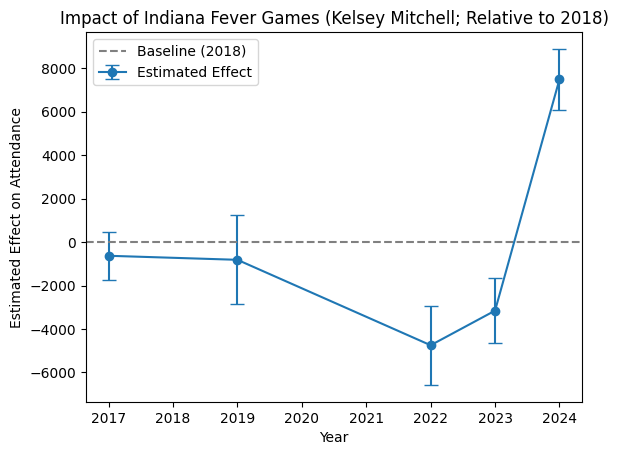

In [5]:
# Indiana Fever (Kelsey Mitchell; 2018-2024)
id_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for Fever Games (2017-2024)
id_attendance_df['ID_Fever_Game'] = (id_attendance_df['Home Team'] == 'Indiana Fever') & (id_attendance_df['Year'].between(2017, 2024))

# 🚀 3. Create Interaction Terms for Each Year (Skip 2018 as the Reference (also skip 2021: no data)); no data for 2020 (COVID year) so I will also omit it)
for year in [2017, 2019, 2022, 2023, 2024]:
    col_name = f'INX{year}'
    id_attendance_df[col_name] = id_attendance_df['ID_Fever_Game'].astype(int)
    id_attendance_df.loc[id_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
id_attendance_df = id_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2017 + INX2019 + INX2022 + INX2023 + INX2024 + EntityEffects + TimeEffects - TimeEffects[2018]',
    id_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2017, 2019, 2022, 2023, 2024]  # Excluding 2018 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2018)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of Indiana Fever Games (Kelsey Mitchell; Relative to 2018)")
plt.legend()
plt.show()

                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0133
Estimator:                   PanelOLS   R-squared (Between):             -0.0026
No. Observations:                6214   R-squared (Within):               0.0191
Date:                Wed, Apr 30 2025   R-squared (Overall):             -0.0034
Time:                        04:52:20   Log-likelihood                -5.785e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      41.499
Entities:                          29   P-value                           0.0000
Avg Obs:                       214.28   Distribution:                  F(2,6157)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             17.725
                            

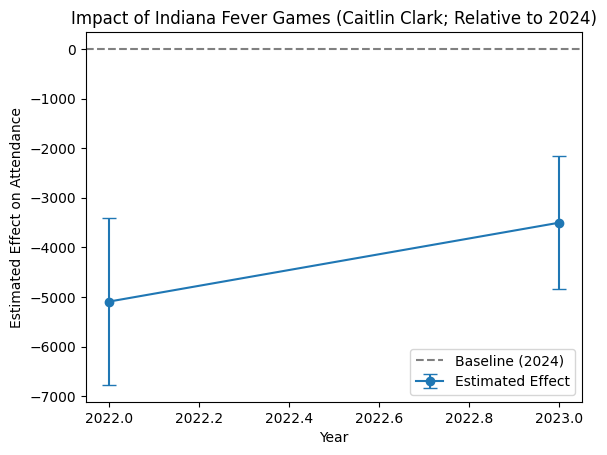

In [6]:
# Indiana Fever (Caitlin Clark; 2024)
id_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for Fever Games (2022-2024)
id_attendance_df['ID_Fever_Game'] = (id_attendance_df['Home Team'] == 'Indiana Fever') & (id_attendance_df['Year'].between(2022, 2024))

# 🚀 3. Create Interaction Terms for Each Year (Skip 2024 as the Reference; no data for 2020 (COVID year) so I will also omit it)
for year in [2022, 2023]:
    col_name = f'INX{year}'
    id_attendance_df[col_name] = id_attendance_df['ID_Fever_Game'].astype(int)
    id_attendance_df.loc[id_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
id_attendance_df = id_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2022 + INX2023 + EntityEffects + TimeEffects - TimeEffects[2024]',
    id_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2022, 2023]  # Excluding 2024 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2024)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of Indiana Fever Games (Caitlin Clark; Relative to 2024)")
plt.legend()
plt.show()